<a href="https://colab.research.google.com/github/Mozassam/ML/blob/master/108_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:

import numpy as np
import pandas as pd
from sklearn.datasets import make_classification

In [12]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)


In [13]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,-1.443041,-0.852925,0.484662,-2.459833,-1.019006,0
1,-0.541034,0.909503,-0.223436,0.860324,-1.048591,0
2,-0.555602,-2.178435,-1.693304,-1.117650,-0.197882,1
3,-2.224195,-1.943484,1.078382,-3.044596,-0.069263,0
4,0.032953,-2.956316,0.722693,-1.231328,0.801383,1


In [14]:
# function for row sampling

def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)

In [15]:
# function for feature sampling
def sample_features(df,percent):
  cols = random.sample(df.columns.tolist()[:-1],int(percent*(df.shape[1]-1)))
  new_df = df[cols]
  new_df['target'] = df['target']
  return new_df

In [16]:
# function for combined sampling

def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)

In [17]:
import random
df1 = combined_sampling(df,0.5,0.5)

/tmp/ipykernel_860/3275485051.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [18]:
df2 = combined_sampling(df,0.5,0.5)

/tmp/ipykernel_860/3275485051.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [21]:
df3 = combined_sampling(df,0.5,0.5)
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['col2', 'col3', 'target'], dtype='object')
Index(['col4', 'col1', 'target'], dtype='object')
Index(['col3', 'col4', 'target'], dtype='object')


/tmp/ipykernel_860/3275485051.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [20]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [24]:
clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])

DecisionTreeClassifier()

In [22]:
from sklearn.tree import plot_tree

[Text(0.5131578947368421, 0.95, 'x[1] <= 1.099\ngini = 0.493\nsamples = 50\nvalue = [22.0, 28.0]'),
 Text(0.2894736842105263, 0.85, 'x[1] <= -1.134\ngini = 0.464\nsamples = 30\nvalue = [19, 11]'),
 Text(0.40131578947368424, 0.8999999999999999, 'True  '),
 Text(0.23684210526315788, 0.75, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.34210526315789475, 0.75, 'x[1] <= 0.741\ngini = 0.436\nsamples = 28\nvalue = [19, 9]'),
 Text(0.21052631578947367, 0.65, 'x[1] <= -0.084\ngini = 0.488\nsamples = 19\nvalue = [11, 8]'),
 Text(0.10526315789473684, 0.55, 'x[0] <= 1.322\ngini = 0.245\nsamples = 7\nvalue = [6, 1]'),
 Text(0.05263157894736842, 0.45, 'gini = 0.0\nsamples = 6\nvalue = [6, 0]'),
 Text(0.15789473684210525, 0.45, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.3157894736842105, 0.55, 'x[0] <= 0.436\ngini = 0.486\nsamples = 12\nvalue = [5, 7]'),
 Text(0.2631578947368421, 0.45, 'x[0] <= -3.202\ngini = 0.42\nsamples = 10\nvalue = [3, 7]'),
 Text(0.21052631578947367, 0.35, 'gini 

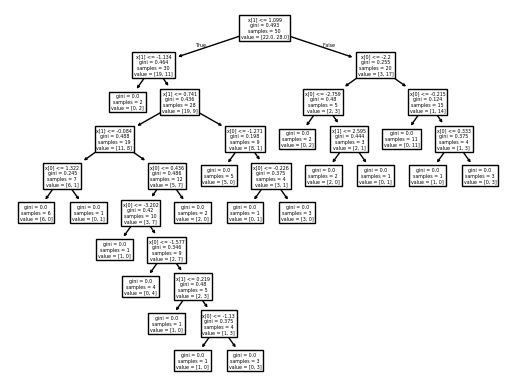

In [25]:
plot_tree(clf1)

[Text(0.38461538461538464, 0.9375, 'x[1] <= -0.777\ngini = 0.471\nsamples = 50\nvalue = [31, 19]'),
 Text(0.23076923076923078, 0.8125, 'x[0] <= -2.83\ngini = 0.111\nsamples = 17\nvalue = [16, 1]'),
 Text(0.3076923076923077, 0.875, 'True  '),
 Text(0.15384615384615385, 0.6875, 'x[1] <= -1.851\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.07692307692307693, 0.5625, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.23076923076923078, 0.5625, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.3076923076923077, 0.6875, 'gini = 0.0\nsamples = 15\nvalue = [15, 0]'),
 Text(0.5384615384615384, 0.8125, 'x[0] <= -1.684\ngini = 0.496\nsamples = 33\nvalue = [15, 18]'),
 Text(0.46153846153846156, 0.875, '  False'),
 Text(0.46153846153846156, 0.6875, 'gini = 0.0\nsamples = 5\nvalue = [5, 0]'),
 Text(0.6153846153846154, 0.6875, 'x[0] <= -0.493\ngini = 0.459\nsamples = 28\nvalue = [10, 18]'),
 Text(0.46153846153846156, 0.5625, 'x[0] <= -0.927\ngini = 0.231\nsamples = 15\nvalue = [2, 13]'),
 Te

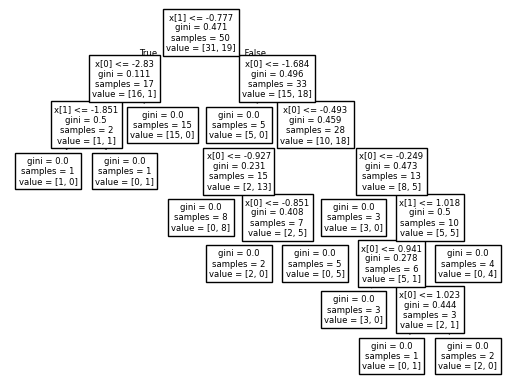

In [26]:

plot_tree(clf2)

[Text(0.6617647058823529, 0.95, 'x[0] <= 1.202\ngini = 0.499\nsamples = 50\nvalue = [26, 24]'),
 Text(0.5, 0.85, 'x[0] <= -0.987\ngini = 0.444\nsamples = 30\nvalue = [20, 10]'),
 Text(0.5808823529411764, 0.8999999999999999, 'True  '),
 Text(0.4411764705882353, 0.75, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.5588235294117647, 0.75, 'x[0] <= 1.156\ngini = 0.408\nsamples = 28\nvalue = [20, 8]'),
 Text(0.5, 0.65, 'x[0] <= 1.099\ngini = 0.454\nsamples = 23\nvalue = [15, 8]'),
 Text(0.4411764705882353, 0.55, 'x[1] <= -0.764\ngini = 0.408\nsamples = 21\nvalue = [15, 6]'),
 Text(0.29411764705882354, 0.45, 'x[1] <= -0.779\ngini = 0.473\nsamples = 13\nvalue = [8, 5]'),
 Text(0.23529411764705882, 0.35, 'x[0] <= 0.092\ngini = 0.397\nsamples = 11\nvalue = [8, 3]'),
 Text(0.11764705882352941, 0.25, 'x[1] <= -2.412\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.058823529411764705, 0.15, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.17647058823529413, 0.15, 'gini = 0.0\nsamples 

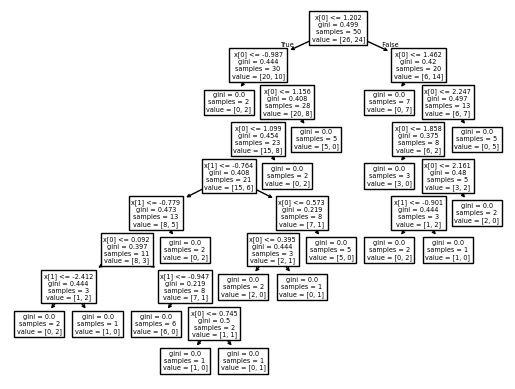

In [27]:

plot_tree(clf3)

In [28]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [29]:
clf2.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [30]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [31]:
df.sample(14,replace=True)

,col1,col2,col3,col4,col5,target
3,-2.224195,-1.943484,1.078382,-3.044596,-0.069263,0
21,1.864290,-0.631490,0.162173,1.591087,-1.239287,1
44,-0.590116,-2.800953,1.949204,-1.765930,1.363952,1
55,-1.683901,0.778646,0.255580,0.763919,-0.106125,0
29,1.021655,-0.103298,1.115750,0.265894,1.883481,0
84,0.181185,-2.309178,-0.269682,-1.845101,-0.164128,0
5,1.393020,-1.034056,2.564505,-0.530067,1.055274,1
27,0.379913,-0.232978,2.014491,-0.510426,-1.681910,0
33,-1.213359,-0.755090,0.661126,0.035120,-0.587857,0
65,-0.898407,-1.380750,1.861547,-0.748579,-0.045455,1
